# 03 – Analysis & Models
Tests the four hypotheses on the clean tables from `02_transform_load`, then applies two brief models.

| # | Hypothesis | Section |
|---|---|---|
| — | Context: how partner shares moved, and where China's lost share went | 1–2 |
| H1 | Mexico's gains are concentrated in a few products | 3–4 |
| H2 | Mexico gains where China loses (substitution) | 5 |
| H3 | It is "China+1", not Mexico-specific | 6 |
| Models | K-means segmentation of products; regression vs. Random Forest | 7–9 |

**Input:** `data/nearshoring.db` · **Output:** charts in `figures/`

## 0. Setup
Loads the two analysis tables from SQLite. `material` and `hs_revision_flag` come back from SQLite as 0/1, so they are cast back to booleans.

In [119]:
import os, sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score, KFold
import statsmodels.formula.api as smf

BASE = ".."
FIG = f"{BASE}/figures"
os.makedirs(FIG, exist_ok=True)

con = sqlite3.connect(f"{BASE}/data/nearshoring.db")
annual = pd.read_sql("SELECT * FROM imports_annual", con)
feat = pd.read_sql("SELECT * FROM hs4_features", con)
feat["material"] = feat["material"].astype(bool)
feat["hs_revision_flag"] = feat["hs_revision_flag"].astype(bool)

PARTNERS = ["MX", "CN", "TW", "ROW"]
NAMES = {"MX": "Mexico", "CN": "China", "TW": "Taiwan", "ROW": "Rest of world"}
COLORS = {"Mexico": "#2a9d8f", "China": "#e76f51", "Taiwan": "#264653", "Rest of world": "#adb5bd"}

sns.set_theme(style="whitegrid")
plt.rcParams.update({"axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlesize": 13})

def save(fig, name):
    fig.savefig(f"{FIG}/{name}.png", dpi=200, bbox_inches="tight")

print("annual:", annual.shape, "| features:", feat.shape)

annual: (11142, 12) | features: (1238, 37)


### Analysis sample
Share changes are only meaningful for products that are large enough and exist in both periods.
The sample keeps **material** products (≥ USD 100M of baseline imports) and drops codes affected by the 2022 HS revision.

In [120]:
an = feat[feat["material"] & ~feat["hs_revision_flag"]].copy()
print(f"Products: {len(feat):,} in total → {len(an):,} in the analysis sample")
print(f"The sample covers {an['world_recent_bn'].sum() / feat['world_recent_bn'].sum():.1%} of recent US imports")

Products: 1,238 in total → 994 in the analysis sample
The sample covers 99.3% of recent US imports


**8803 → 8807 (aircraft parts).** The 2022 HS revision moved aircraft parts from 8803 to 8807. Treated as one product, the share changes are:

In [121]:
pair = feat[feat["hs4"].isin(["8803", "8807"])]
for p in PARTNERS:
    base_share = (pair[f"share_{p}_base"].fillna(0) * pair["world_base_bn"]).sum() / pair["world_base_bn"].sum()
    rec_share = (pair[f"share_{p}_recent"].fillna(0) * pair["world_recent_bn"]).sum() / pair["world_recent_bn"].sum()
    print(f"{NAMES[p]:<14} {base_share:6.1%} → {rec_share:6.1%}  ({(rec_share - base_share) * 100:+.1f} pp)")

Mexico           6.7% →   9.0%  (+2.3 pp)
China            2.8% →   2.3%  (-0.5 pp)
Taiwan           0.5% →   0.6%  (+0.1 pp)
Rest of world   90.0% →  88.1%  (-1.8 pp)


## 1. Context: partner shares of US imports, 2017–2025

In [122]:
tot = annual.groupby("year")[PARTNERS + ["WORLD"]].sum() / 1e9
shares = tot[PARTNERS].div(tot["WORLD"], axis=0) * 100
shares.columns = [NAMES[p] for p in PARTNERS]
display(tot.round(1).rename(columns=NAMES))
shares.round(1)

,Mexico,China,Taiwan,Rest of world,WORLD
year,,,,,
2017,312.7,505.2,42.4,1479.3,2339.6
2018,343.7,538.5,45.7,1608.2,2536.1
2019,356.1,449.1,54.2,1632.3,2491.7
2020,323.5,432.5,60.4,1515.0,2331.5
2021,382.6,504.2,77.0,1864.7,2828.5
2022,452.0,536.3,91.7,2159.7,3239.7
2023,472.9,427.2,87.8,2088.6,3076.6
2024,503.1,440.3,116.3,2204.2,3263.9
2025,534.3,308.7,201.4,2370.2,3414.5


,Mexico,China,Taiwan,Rest of world
year,,,,
2017,13.4,21.6,1.8,63.2
2018,13.6,21.2,1.8,63.4
2019,14.3,18.0,2.2,65.5
2020,13.9,18.6,2.6,65.0
2021,13.5,17.8,2.7,65.9
2022,14.0,16.6,2.8,66.7
2023,15.4,13.9,2.9,67.9
2024,15.4,13.5,3.6,67.5
2025,15.6,9.0,5.9,69.4


### 1b. What drove Taiwan's 2025 jump?
Taiwan's top gaining products are all computing hardware, and computers (8471) surge
for both Taiwan and Mexico in 2024–25 while China collapses: consistent with the
AI-server boom rather than geopolitics.

In [123]:
tw_top = feat.nlargest(5, "contrib_TW_pp")[["hs4", "hs4_desc", "contrib_TW_pp", "gain_TW_bn_yr"]]
display(tw_top)
annual.loc[annual["hs4"] == "8471", ["year", "TW", "MX", "CN"]].set_index("year").div(1e9).round(1)

,hs4,hs4_desc,contrib_TW_pp,gain_TW_bn_yr
1027,8471,AUTOMATIC DATA PROCESS MACHINES; MAGN READER ETC,1.134356,38.129448
1029,8473,PARTS ETC FOR TYPEWRITERS & OTHER OFFICE MACHINES,0.759165,25.585417
1084,8542,"ELECTRONIC INTEGRATED CIRCUITS & MICROASSEMBL,...",0.163821,6.596824
1060,8517,PHONE SETS; OTH APPARAT TRANS/RECEP VOICE/IMG/...,0.119568,4.786224
1065,8523,PREPARED UNRECORDED MEDIA (NO FILM) FOR SOUND ...,0.031974,1.588527


,TW,MX,CN
year,,,
2017,2.6,20.0,50.4
2018,2.9,26.3,51.4
2019,6.0,27.2,44.7
2020,8.7,26.4,52.7
2021,8.9,28.4,61.3
2022,11.1,36.3,54.8
2023,14.3,27.7,39.1
2024,26.1,48.3,36.2
2025,85.5,89.9,10.8


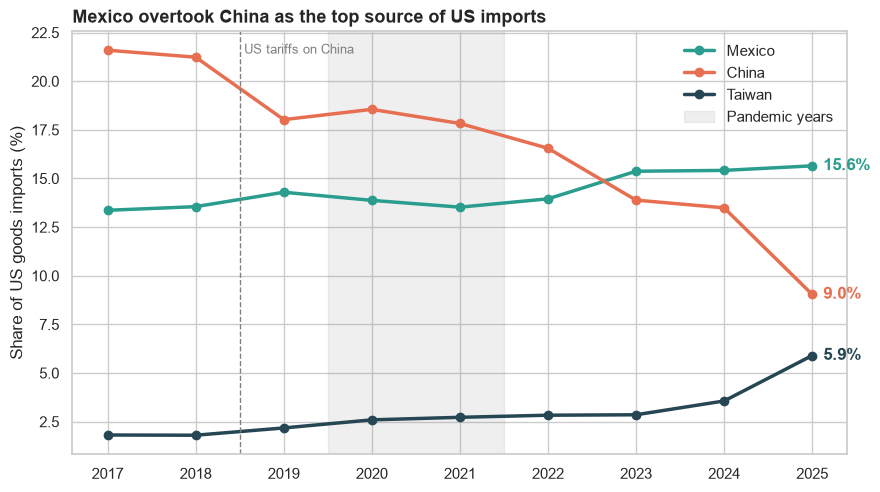

In [124]:
fig, ax = plt.subplots(figsize=(10, 5.5))
for c in ["Mexico", "China", "Taiwan"]:
    ax.plot(shares.index, shares[c], marker="o", lw=2.5, color=COLORS[c], label=c)
    ax.annotate(f"{shares[c].iloc[-1]:.1f}%", (shares.index[-1], shares[c].iloc[-1]),
                xytext=(8, 0), textcoords="offset points", va="center",
                color=COLORS[c], fontweight="bold")
ax.axvspan(2019.5, 2021.5, color="grey", alpha=0.12, label="Pandemic years")
ax.axvline(2018.5, color="grey", ls="--", lw=1)
ax.text(2018.55, 0.97, "US tariffs on China", transform=ax.get_xaxis_transform(),
        fontsize=9, color="grey", va="top")
ax.set_title("Mexico overtook China as the top source of US imports")
ax.set_ylabel("Share of US goods imports (%)")
ax.set_xlabel("")
ax.set_xticks(shares.index)
ax.legend(frameon=False, loc="upper right")
save(fig, "01_shares")
plt.show()

## 2. Where did China's lost share go?
Change in each partner's share of total US imports, baseline (2017–19) vs. recent (2023–25).
The four changes add up to zero, so this shows exactly who captured China's loss.

China's share change: -8.20 pp
  Mexico         +1.74 pp  → 21% of China's loss
  Taiwan         +2.22 pp  → 27% of China's loss
  Rest of world  +4.24 pp  → 52% of China's loss


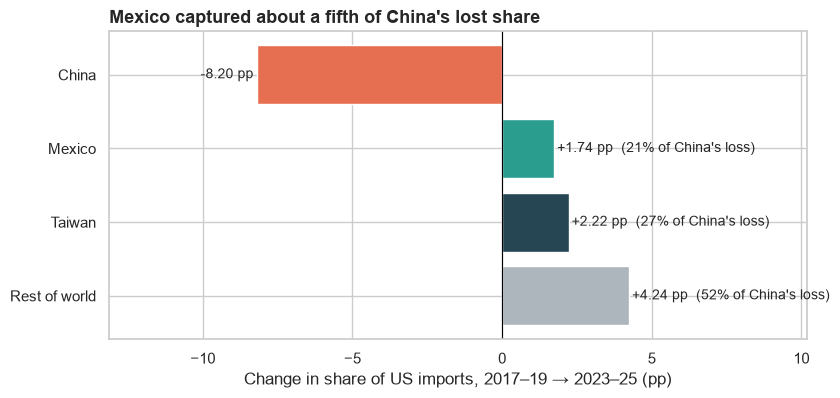

In [125]:
agg = pd.Series({NAMES[p]: feat[f"contrib_{p}_pp"].sum() for p in PARTNERS})
china_loss = -agg["China"]
print(f"China's share change: {agg['China']:+.2f} pp")
for k in ["Mexico", "Taiwan", "Rest of world"]:
    print(f"  {k:<14} {agg[k]:+.2f} pp  → {agg[k] / china_loss:.0%} of China's loss")

order = ["China", "Mexico", "Taiwan", "Rest of world"]
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(order[::-1], agg[order[::-1]], color=[COLORS[k] for k in order[::-1]])
for i, k in enumerate(order[::-1]):
    v = agg[k]
    label = f"{v:+.2f} pp" + ("" if k == "China" else f"  ({v / china_loss:.0%} of China's loss)")
    ax.text(v + (0.1 if v >= 0 else -0.1), i, label, va="center", ha="left" if v >= 0 else "right", fontsize=10)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlim(agg.min() * 1.6, agg.max() * 2.4)
ax.set_title("Mexico captured about a fifth of China's lost share")
ax.set_xlabel("Change in share of US imports, 2017–19 → 2023–25 (pp)")
save(fig, "02_where_china_share_went")
plt.show()

## 3. H1 – Are Mexico's gains concentrated?
Products are ranked by their **contribution** to Mexico's aggregate share change (value-weighted, so it sums to the total).
The curve shows how quickly a handful of products account for the whole net gain.

In [126]:
mx = feat.sort_values("contrib_MX_pp", ascending=False).reset_index(drop=True)
net = mx["contrib_MX_pp"].sum()
mx["cum"] = mx["contrib_MX_pp"].cumsum()
mx["rank"] = mx.index + 1

print(f"Mexico's net share change: {net:+.2f} pp")
for n in [1, 5, 10, 20, 50]:
    print(f"  Top {n:>2} products: {mx['cum'].iloc[n - 1]:+.2f} pp = {mx['cum'].iloc[n - 1] / net:.0%} of the net gain")
n_net = int((mx["cum"] >= net).idxmax()) + 1
print(f"Only {n_net} products (of {len(mx):,}) are needed to reach Mexico's full net gain")

Mexico's net share change: +1.74 pp
  Top  1 products: +0.70 pp = 40% of the net gain
  Top  5 products: +1.09 pp = 63% of the net gain
  Top 10 products: +1.43 pp = 82% of the net gain
  Top 20 products: +1.79 pp = 103% of the net gain
  Top 50 products: +2.18 pp = 125% of the net gain
Only 18 products (of 1,238) are needed to reach Mexico's full net gain


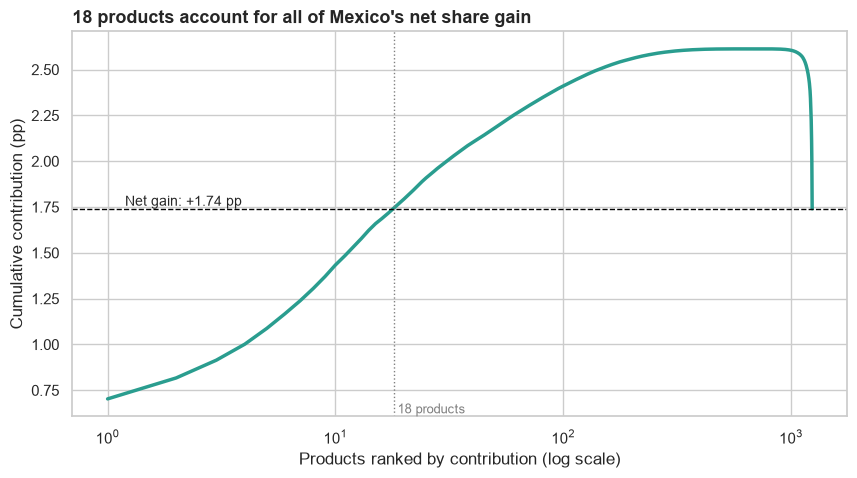

In [127]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(mx["rank"], mx["cum"], color=COLORS["Mexico"], lw=2.5)
ax.axhline(net, color="black", ls="--", lw=1)
ax.text(1.1, net, f"  Net gain: {net:+.2f} pp", va="bottom", fontsize=10)
ax.axvline(n_net, color="grey", ls=":", lw=1)
ax.text(n_net, ax.get_ylim()[0], f" {n_net} products", fontsize=9, color="grey", va="bottom")
ax.set_xscale("log")
ax.set_title(f"{n_net} products account for all of Mexico's net share gain")
ax.set_xlabel("Products ranked by contribution (log scale)")
ax.set_ylabel("Cumulative contribution (pp)")
save(fig, "03_mx_concentration")
plt.show()

In [128]:
for t in [0.20, 0.30, 0.40, 0.50]:
    legacy = an["share_MX_base"] >= t
    subst = ~legacy & ~an["sector"].isin(["Agri-food", "Minerals & fuels"]) & (an["d_share_CN_pp"] < 0)
    pos = an["contrib_MX_pp"].clip(lower=0)
    print(f"Threshold {t:.0%}: substitution = {pos[subst].sum() / pos.sum():.0%} of gains, legacy = {pos[legacy].sum() / pos.sum():.0%}")

Threshold 20%: substitution = 25% of gains, legacy = 63%
Threshold 30%: substitution = 63% of gains, legacy = 23%
Threshold 40%: substitution = 70% of gains, legacy = 16%
Threshold 50%: substitution = 74% of gains, legacy = 10%


### 3b. Where did Mexico lose share?
The contribution is split into a **within** effect (Mexico's share change inside the product)
and a **mix** effect (the product growing or shrinking in total US imports).
Most of Mexico's negative contributions are mix effects in shrinking categories (TVs, crude oil),
where Mexico often *gained* share. Real within-product losses (gold, optics, tractors) are not
China-related. In phones and lighting, China lost a quarter of the market and Mexico captured none of it.

In [129]:
peak = mx["cum"].max()
peak_rank = int(mx["cum"].idxmax()) + 1
print(f"Winners peak at {peak:+.2f} pp (after {peak_rank} products); losses then subtract {peak - net:.2f} pp\n")

cols = ["hs4", "hs4_desc", "contrib_MX_pp", "within_MX_pp", "mix_MX_pp", "gain_MX_bn_yr",
           "share_MX_base", "d_share_MX_pp", "d_share_CN_pp", "d_share_ROW_pp"]
feat.nsmallest(10, "contrib_MX_pp")[cols].round(3)

w, m = feat["within_MX_pp"].sum(), feat["mix_MX_pp"].sum()
print(f"\nMexico total: within {w:+.2f} pp + mix {m:+.2f} pp = {w + m:+.2f} pp")

Winners peak at +2.61 pp (after 658 products); losses then subtract 0.87 pp


Mexico total: within +1.55 pp + mix +0.20 pp = +1.74 pp


## 4. H1 – What kind of gains are they?
Not every gain is nearshoring. Each material product is classified with simple, transparent rules (applied in this order):
1. **Resource / brand-driven** – agri-food and fuels (tequila, beer, refined oil): tied to geography, not relocatable.
2. **Legacy integration** – Mexico already had ≥ 30% of US imports in the baseline (NAFTA-era supply chains).
3. **Substitution of China** – China lost share in the same product.
4. **Other growth** – everything else.

In [130]:
def gain_type(r):
    if r["sector"] in ["Agri-food", "Minerals & fuels"]:
        return "Resource / brand-driven"
    if r["share_MX_base"] >= 0.30:
        return "Legacy integration"
    if r["d_share_CN_pp"] < 0:
        return "Substitution of China"
    return "Other growth"

an["gain_type"] = an.apply(gain_type, axis=1)
TYPE_COLORS = {"Substitution of China": "#2a9d8f", "Legacy integration": "#e9c46a",
               "Resource / brand-driven": "#8d99ae", "Other growth": "#ced4da"}

gainers = an[an["contrib_MX_pp"] > 0]
by_type = (gainers.groupby("gain_type")
                  .agg(products=("hs4", "size"), contrib_MX_pp=("contrib_MX_pp", "sum"),
                       gain_MX_bn_yr=("gain_MX_bn_yr", "sum"))
                  .sort_values("contrib_MX_pp", ascending=False))
by_type["share_of_gains"] = by_type["contrib_MX_pp"] / by_type["contrib_MX_pp"].sum()
by_type.round(3)

,products,contrib_MX_pp,gain_MX_bn_yr,share_of_gains
gain_type,,,,
Substitution of China,320,1.609,78.605,0.628
Legacy integration,26,0.479,42.642,0.187
Resource / brand-driven,133,0.388,20.609,0.152
Other growth,62,0.086,17.192,0.034


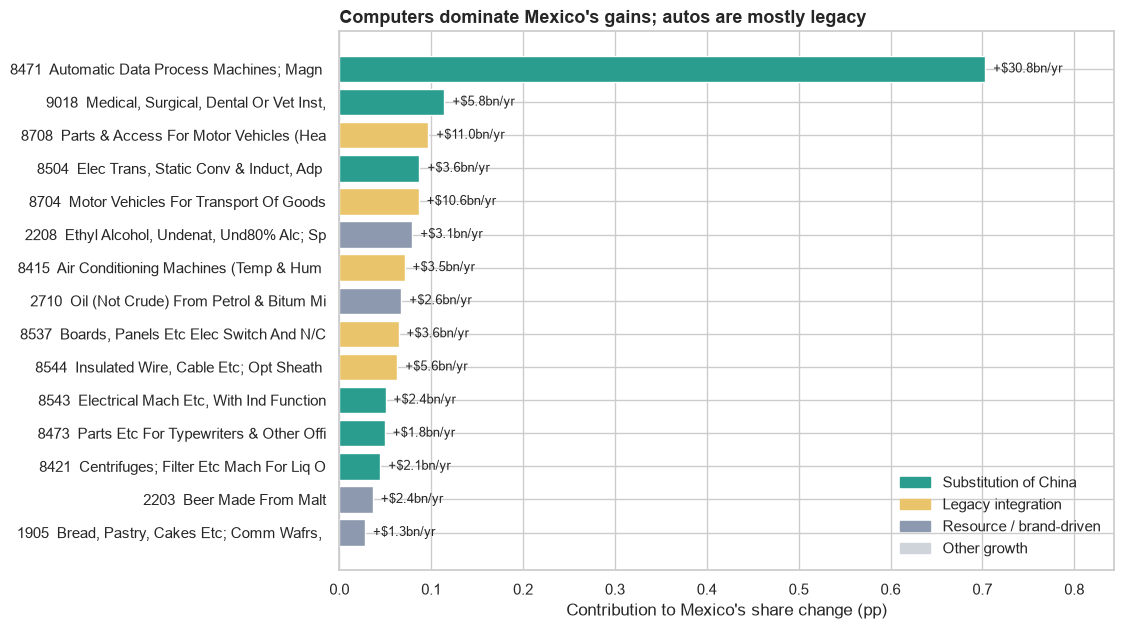

In [131]:
top = an.nlargest(15, "contrib_MX_pp").iloc[::-1]
labels = top["hs4"] + "  " + top["hs4_desc"].str.title().str.slice(0, 38)

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(labels, top["contrib_MX_pp"], color=top["gain_type"].map(TYPE_COLORS))
for i, (c, g) in enumerate(zip(top["contrib_MX_pp"], top["gain_MX_bn_yr"])):
    ax.text(c, i, f"  +${g:.1f}bn/yr", va="center", fontsize=9)
ax.set_xlim(0, top["contrib_MX_pp"].max() * 1.2)
handles = [plt.Rectangle((0, 0), 1, 1, color=v) for v in TYPE_COLORS.values()]
ax.legend(handles, TYPE_COLORS.keys(), frameon=False, loc="lower right")
ax.set_title("Computers dominate Mexico's gains; autos are mostly legacy")
ax.set_xlabel("Contribution to Mexico's share change (pp)")
save(fig, "04_mx_top15_by_type")
plt.show()

In [132]:
for t in [0.20, 0.30, 0.40, 0.50]:
    legacy = an["share_MX_base"] >= t
    subst = ~legacy & ~an["sector"].isin(["Agri-food", "Minerals & fuels"]) & (an["d_share_CN_pp"] < 0)
    pos = an["contrib_MX_pp"].clip(lower=0)
    print(f"Threshold {t:.0%}: substitution = {pos[subst].sum() / pos.sum():.0%} of gains, legacy = {pos[legacy].sum() / pos.sum():.0%}")

Threshold 20%: substitution = 25% of gains, legacy = 63%
Threshold 30%: substitution = 63% of gains, legacy = 23%
Threshold 40%: substitution = 70% of gains, legacy = 16%
Threshold 50%: substitution = 74% of gains, legacy = 10%


In [133]:
   an.loc[an["hs4"] == "8471", ["share_MX_base", "share_CN_base", "d_share_MX_pp", "d_share_CN_pp"]]

,share_MX_base,share_CN_base,d_share_MX_pp,d_share_CN_pp
1027,0.276486,0.55012,5.916289,-37.598582


**Sensitivity:** the result depends on the legacy threshold. At 20%, only 25% of Mexico's gains count as
substitution; at 30–50%, 63–74% do. The swing is driven by computers (8471): Mexico already supplied 27.6%
of US computer imports in 2017–19, so its gain there (+5.9 pp) expanded an existing position. Even in this,
its best product, Mexico captured only about a sixth of China's −37.6 pp loss.

## 5. H2 – Does Mexico gain where China loses?
Each dot is one product; size = recent US imports. If Mexico substitutes China, large dots cluster in the **top-left** quadrant
(China down, Mexico up). Correlations are weighted by trade value so large products count more.

In [134]:
def wcorr(x, y, w):
    mx_, my_ = np.average(x, weights=w), np.average(y, weights=w)
    cov = np.average((x - mx_) * (y - my_), weights=w)
    return cov / np.sqrt(np.average((x - mx_) ** 2, weights=w) * np.average((y - my_) ** 2, weights=w))

w = an["world_recent_bn"]
q = an.assign(
    cn_down=an["d_share_CN_pp"] < 0,
    mx_up=an["d_share_MX_pp"] > 0)
quad = q.groupby(["cn_down", "mx_up"])["world_recent_bn"].sum() / w.sum()

print(f"Weighted correlation, China vs Mexico share change:  {wcorr(an['d_share_CN_pp'], an['d_share_MX_pp'], w):+.2f}")
print(f"Weighted correlation, China vs Taiwan share change:  {wcorr(an['d_share_CN_pp'], an['d_share_TW_pp'], w):+.2f}")
print(f"Share of import value where China lost AND Mexico gained: {quad.get((True, True), 0):.0%}")

Weighted correlation, China vs Mexico share change:  -0.28
Weighted correlation, China vs Taiwan share change:  -0.68
Share of import value where China lost AND Mexico gained: 48%


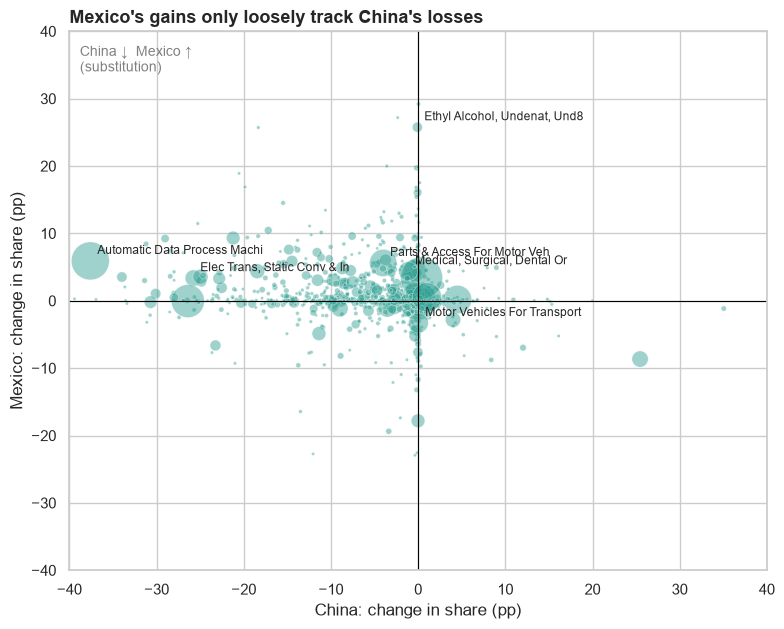

Axes cut at ±40 pp; 9 products fall outside the view.


In [135]:
fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(an["d_share_CN_pp"], an["d_share_MX_pp"], s=an["world_recent_bn"] * 1.5 + 5,
           color=COLORS["Mexico"], alpha=0.45, edgecolor="white", lw=0.5)
ax.axhline(0, color="black", lw=0.8)
ax.axvline(0, color="black", lw=0.8)
for _, r in an.nlargest(6, "contrib_MX_pp").iterrows():
    ax.annotate(r["hs4_desc"].title()[:28], (r["d_share_CN_pp"], r["d_share_MX_pp"]),
                xytext=(5, 5), textcoords="offset points", fontsize=8.5)
lim = 40
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.text(-lim * 0.97, lim * 0.95, "China ↓  Mexico ↑\n(substitution)", fontsize=10, va="top", color="grey")
ax.set_title("Mexico's gains only loosely track China's losses")
ax.set_xlabel("China: change in share (pp)")
ax.set_ylabel("Mexico: change in share (pp)")
save(fig, "05_mx_vs_cn_scatter")
plt.show()
print(f"Axes cut at ±{lim} pp; {((an['d_share_CN_pp'].abs() > lim) | (an['d_share_MX_pp'].abs() > lim)).sum()} products fall outside the view.")

**Result:** H2 is only partially supported. Weighted correlation between China's and Mexico's share changes
is −0.28, against −0.68 for Taiwan: Taiwan is the direct substitute. Substitution is clear in computers,
but China's second-largest loss (phones) went entirely to other countries, and many of Mexico's large gains
(auto parts, medical instruments, tequila) are unrelated to China.

In [136]:
an[an["d_share_CN_pp"] > 15].nlargest(3, "world_recent_bn")[
    ["hs4", "hs4_desc", "world_recent_bn", "d_share_CN_pp", "d_share_MX_pp", "d_share_TW_pp"]].round(2)

,hs4,hs4_desc,world_recent_bn,d_share_CN_pp,d_share_MX_pp,d_share_TW_pp
1050,8507,"ELECTRIC STORAGE BATTERIES, INCL SEPARATORS, P...",88.07,25.45,-8.65,-1.22
138,1518,"ANML,VEG,MICROBIAL FAT OIL&FRACTION,CHEM MOD N...",6.49,35.05,-1.16,0.00
1163,9033,"PTS, NESOI FOR MACHINES,APPLN,INST/APPTS OF CH...",0.63,15.34,-0.53,-1.00


## 6. H3 – Is it Mexico, or "China+1"?
Contribution to each partner's share change by sector. Green = gained share, red = lost.
If the shift is "China+1", Taiwan and the rest of the world gain in the same sectors as Mexico.

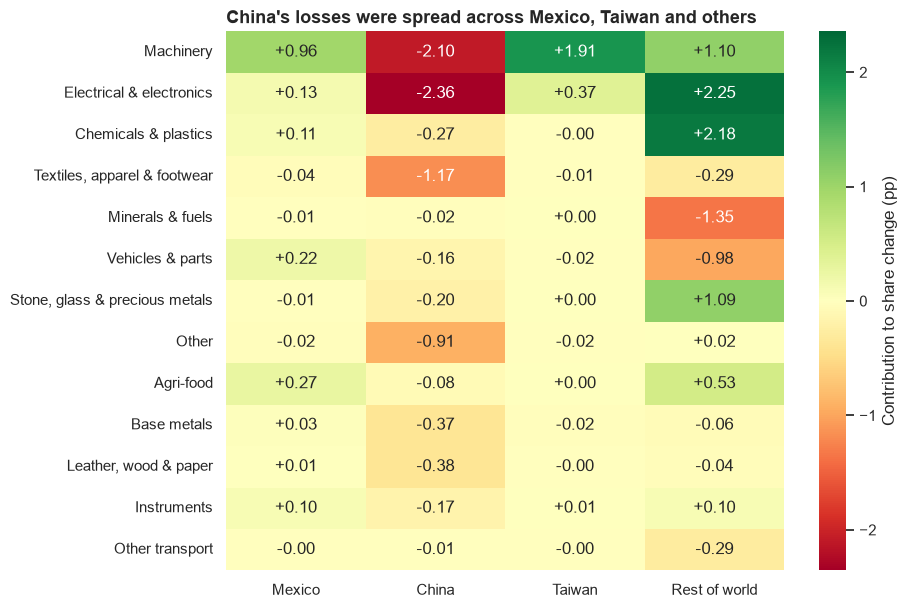

In [137]:
sec = feat.groupby("sector")[[f"contrib_{p}_pp" for p in PARTNERS]].sum()
sec.columns = [NAMES[p] for p in PARTNERS]
sec = sec.loc[sec.abs().sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(9, 7))
v = sec.abs().max().max()
sns.heatmap(sec, annot=True, fmt="+.2f", cmap="RdYlGn", center=0, vmin=-v, vmax=v,
            cbar_kws={"label": "Contribution to share change (pp)"}, ax=ax)
ax.set_title("China's losses were spread across Mexico, Taiwan and others")
ax.set_xlabel("")
ax.set_ylabel("")
save(fig, "06_sector_heatmap")
plt.show()

In [138]:
top_mx = set(an.nlargest(50, "contrib_MX_pp")["hs4"])
top_tw = set(an.nlargest(50, "contrib_TW_pp")["hs4"])
top_row = set(an.nlargest(50, "contrib_ROW_pp")["hs4"])
print("Overlap of each partner's top-50 gaining products with Mexico's top 50:")
print(f"  Taiwan:        {len(top_mx & top_tw)} products")
print(f"  Rest of world: {len(top_mx & top_row)} products")
print("Shared with Taiwan:", ", ".join(sorted(top_mx & top_tw)))

Overlap of each partner's top-50 gaining products with Mexico's top 50:
  Taiwan:        14 products
  Rest of world: 20 products
Shared with Taiwan: 2710, 7106, 8414, 8419, 8471, 8473, 8479, 8504, 8536, 8537, 8543, 8544, 9018, 9031


   **Result:** H3 supported. China's losses are spread across partners. In machinery, Taiwan captured almost
   twice Mexico's gain; in electrical & electronics and textiles, other countries took nearly all of it.
   Mexico's auto gains came at the expense of other suppliers, not China. 14 of Mexico's top-50 gaining products
   are also Taiwan's, almost all electronics: the two grow together in the same hardware supply chain.
   Rows do not sum to zero: each row's total is how much the whole sector grew or shrank within US imports.

## 7. Model 1 – K-means: segmenting products by trajectory
Each material product is described by five features: the share changes of Mexico, China and Taiwan, its size (log of recent imports)
and the growth of US demand (CAGR). Rest of world is left out because the four share changes always sum to zero.

Extreme values are capped at the 1st and 99th percentiles and all features are standardised, so no single feature dominates the distances.

Products clustered: 994


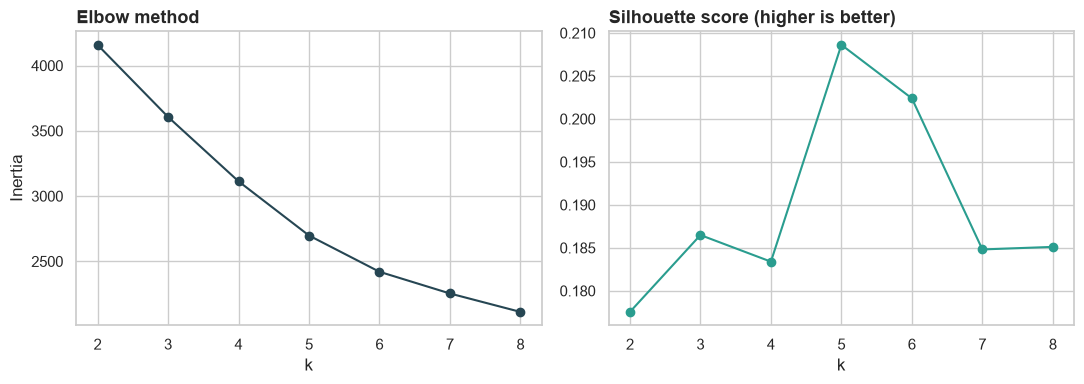

In [139]:
FEATURES = ["d_share_MX_pp", "d_share_CN_pp", "d_share_TW_pp", "log_size", "world_cagr"]
an["log_size"] = np.log10(an["world_recent_bn"] * 1000)          # log10 of USD millions
km_df = an.dropna(subset=FEATURES).copy()
X_raw = km_df[FEATURES]
X_raw = X_raw.clip(lower=X_raw.quantile(0.01), upper=X_raw.quantile(0.99), axis=1)
X = StandardScaler().fit_transform(X_raw)
print("Products clustered:", len(km_df))

ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    m = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertia.append(m.inertia_)
    sil.append(silhouette_score(X, m.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(ks, inertia, marker="o", color=COLORS["Taiwan"])
axes[0].set_title("Elbow method")
axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia")
axes[1].plot(ks, sil, marker="o", color=COLORS["Mexico"])
axes[1].set_title("Silhouette score (higher is better)")
axes[1].set_xlabel("k")
plt.tight_layout()
save(fig, "07_kmeans_k_selection")
plt.show()

Pick **K** from the elbow (where the curve flattens) and the silhouette score, then run the next cell.

In [140]:
K = 5                                                            # adjust after reading the charts above
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X)
km_df["cluster"] = km.labels_

profile = (km_df.groupby("cluster")
                .agg(products=("hs4", "size"),
                     recent_imports_bn=("world_recent_bn", "sum"),
                     d_share_MX_pp=("d_share_MX_pp", "median"),
                     d_share_CN_pp=("d_share_CN_pp", "median"),
                     d_share_TW_pp=("d_share_TW_pp", "median"),
                     world_cagr=("world_cagr", "median"),
                     contrib_MX_pp=("contrib_MX_pp", "sum")))
display(profile.round(2))

for c in range(K):
    names = km_df[km_df["cluster"] == c].nlargest(5, "world_recent_bn")["hs4_desc"].str.title().str.slice(0, 35)
    print(f"Cluster {c}: " + " | ".join(names))

,products,recent_imports_bn,d_share_MX_pp,d_share_CN_pp,d_share_TW_pp,world_cagr,contrib_MX_pp
cluster,,,,,,,
0,159,1238.44,0.39,-17.62,-0.05,0.01,0.05
1,310,269.73,0.03,-1.70,-0.00,0.00,-0.08
2,45,1333.79,0.53,-8.51,4.66,0.03,0.69
3,83,385.31,9.41,-3.60,-0.00,0.04,0.38
4,397,6457.53,0.02,-0.66,-0.00,0.06,0.70


Cluster 0: Elec Trans, Static Conv & Induct, A | Furniture Nesoi And Parts Thereof | Seats (Except Barber, Dental, Etc), | Tv Recvrs, Incl Video Monitors & Pr | Electrical Mach Etc, With Ind Funct
Cluster 1: Electric Filament Or Discharge Lamp | Semifinished Products Of Iron Or No | Sulfonamides | Oxygen-Function Amino-Compounds | Revolution & Production Count, Taxi
Cluster 2: Automatic Data Process Machines; Ma | Phone Sets; Oth Apparat Trans/Recep | Parts Etc For Typewriters & Other O | Electronic Integrated Circuits & Mi | Prepared Unrecorded Media (No Film)
Cluster 3: Elec Water, Space & Soil Heaters; H | Ethyl Alcohol, Undenat, Und80% Alc; | Containers (Boxes, Bags Etc), Closu | Beer Made From Malt | Fork-Lift Trucks; Oth Works Trucks 
Cluster 4: Motor Cars & Vehicles For Transport | Crude Oil From Petroleum And Bitumi | Human Blood; Animal Blood; Antisera | Expts Of Repaired Impts; Impts Of R | Medicaments Nesoi, Mixed Or Not, In


   **Result (K = 5).** K was chosen by the silhouette score, which peaks at 5 (0.21); the elbow curve shows no clear break.
   A silhouette around 0.2 means the segments overlap: they describe a continuum rather than sharply separated groups.

   | Segment | Products | Profile (medians) | Examples |
   |---|---|---|---|
   | China retreat, others gain | 159 | China −18 pp, Mexico +0.4 pp | Transformers, furniture, seats, TVs |
   | Small and stable | 310 | Little change, small markets | Lamps, iron, chemicals |
   | Asian tech shift | 45 | China −9 pp, Taiwan +5 pp | Computers, phones, chips |
   | Mexico's own wins | 83 | Mexico +9 pp, China −4 pp | Heaters, forklifts, containers, tequila, beer |
   | Large mature markets | 397 | Little change, USD 6.5tn of imports | Cars, crude oil, pharmaceuticals |

   The model separates two groups that the hypotheses had blended: products where China retreated (Mexico gained little)
   and products where Mexico gained strongly (China was barely involved). This confirms H2 independently:
   Mexico's strongest gains and China's biggest losses are mostly different products.

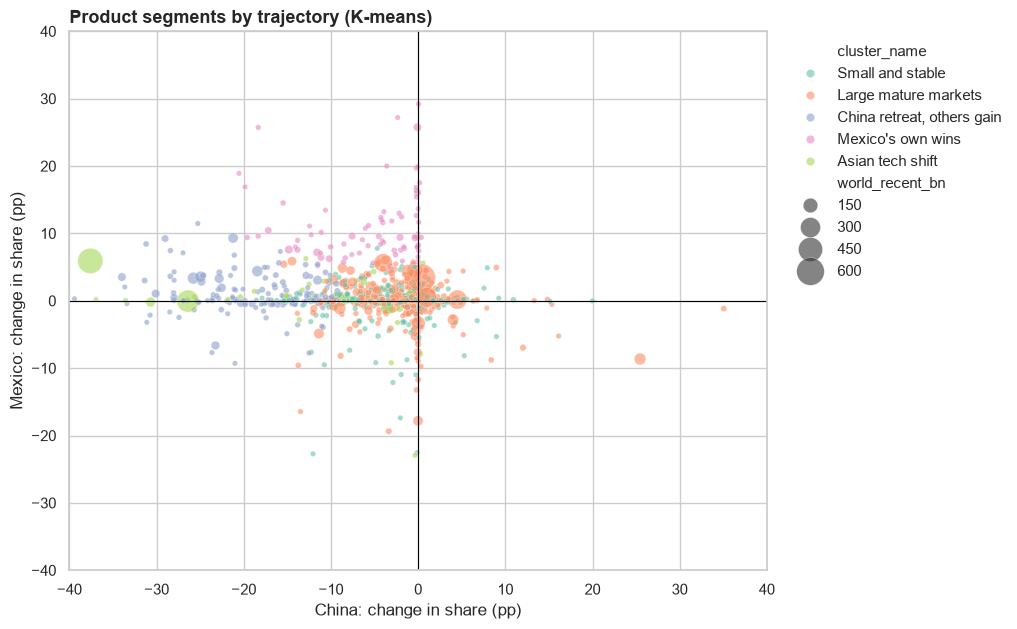

In [141]:
CLUSTER_NAMES = {0: "China retreat, others gain", 1: "Small and stable", 2: "Asian tech shift",
                3: "Mexico's own wins", 4: "Large mature markets"}
km_df["cluster_name"] = km_df["cluster"].map(CLUSTER_NAMES)

fig, ax = plt.subplots(figsize=(9, 7))
sns.scatterplot(data=km_df, x="d_share_CN_pp", y="d_share_MX_pp", hue="cluster_name",
                size="world_recent_bn", sizes=(15, 400), alpha=0.6, palette="Set2", ax=ax)
ax.axhline(0, color="black", lw=0.8)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlim(-40, 40)
ax.set_ylim(-40, 40)
ax.set_title("Product segments by trajectory (K-means)")
ax.set_xlabel("China: change in share (pp)")
ax.set_ylabel("Mexico: change in share (pp)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
save(fig, "08_kmeans_clusters")
plt.show()

## 8. Model 2 – Regression: how much of China's loss does each partner absorb?
Weighted least squares (weights = recent import value), one product per row:

`Δ share of partner ~ Δ share of China`

The coefficient reads as *"for each point of share China loses in a product, this partner gains β points"*.
Because the four share changes always sum to zero, the three coefficients add up to −1: a built-in check.
A second model adds sector dummies, so Mexico's coefficient is estimated **within** sectors.

In [142]:
reg = an.dropna(subset=[f"d_share_{p}_pp" for p in PARTNERS]).copy()
rows = []
for p in ["MX", "TW", "ROW"]:
    m = smf.wls(f"d_share_{p}_pp ~ d_share_CN_pp", data=reg, weights=reg["world_recent_bn"]).fit()
    rows.append({"partner": NAMES[p], "beta_vs_China": m.params["d_share_CN_pp"],
                 "p_value": m.pvalues["d_share_CN_pp"], "R2": m.rsquared})
betas = pd.DataFrame(rows).set_index("partner")
print("Sum of the three betas (should be −1):", round(betas["beta_vs_China"].sum(), 3))
betas.round(3)

Sum of the three betas (should be −1): -1.0


,beta_vs_China,p_value,R2
partner,,,
Mexico,-0.089,0.0,0.077
Taiwan,-0.362,0.0,0.456
Rest of world,-0.549,0.0,0.555


In [143]:
m_sec = smf.wls("d_share_MX_pp ~ d_share_CN_pp + C(sector)", data=reg, weights=reg["world_recent_bn"]).fit()
print(f"Mexico, with sector dummies: beta = {m_sec.params['d_share_CN_pp']:.3f}, "
      f"p = {m_sec.pvalues['d_share_CN_pp']:.3f}, R² = {m_sec.rsquared:.2f}, n = {int(m_sec.nobs)}")
print("Reminder: this is an association across products, not a causal estimate.")

Mexico, with sector dummies: beta = -0.108, p = 0.000, R² = 0.19, n = 994
Reminder: this is an association across products, not a causal estimate.


## 9. Linear regression vs. Random Forest on the same data
The course asks how different libraries behave on the same dataset. Both models predict Mexico's share change from
product characteristics (China's share change, starting shares, size, demand growth, sector), scored with 5-fold cross-validated R².
Taiwan's and the rest of the world's share changes are excluded because, together, they mechanically determine Mexico's.

In [144]:
num = ["d_share_CN_pp", "share_MX_base", "share_CN_base", "log_size", "world_cagr"]
ml = an.dropna(subset=num + ["d_share_MX_pp"]).copy()
Xm = pd.concat([ml[num].clip(lower=ml[num].quantile(0.01), upper=ml[num].quantile(0.99), axis=1),
                pd.get_dummies(ml["sector"], prefix="sec", drop_first=True, dtype=float)], axis=1)
y = ml["d_share_MX_pp"].clip(ml["d_share_MX_pp"].quantile(0.01), ml["d_share_MX_pp"].quantile(0.99))

cv = KFold(n_splits=5, shuffle=True, random_state=42)
models = {"Linear regression": LinearRegression(),
          "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42)}
scores = {name: cross_val_score(m, Xm, y, cv=cv, scoring="r2") for name, m in models.items()}
pd.DataFrame({name: {"mean R²": s.mean(), "std": s.std()} for name, s in scores.items()}).T.round(3)

,mean R²,std
Linear regression,-0.036,0.032
Random Forest,-0.021,0.042


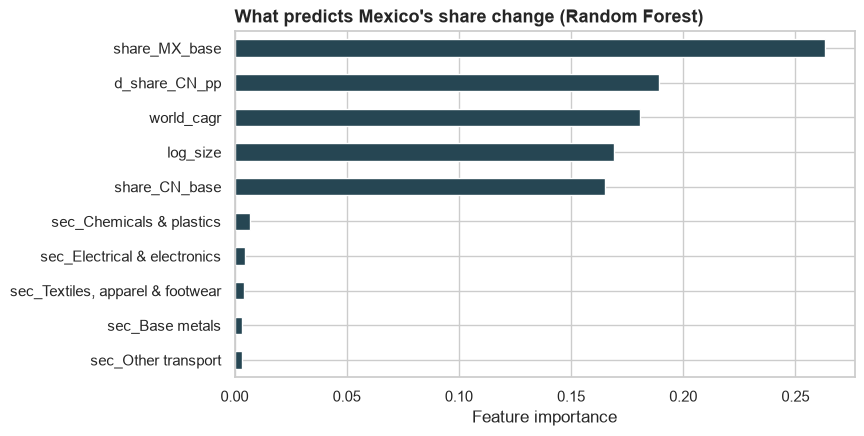

In [145]:
rf = models["Random Forest"].fit(Xm, y)
imp = pd.Series(rf.feature_importances_, index=Xm.columns).sort_values(ascending=False).head(10)

fig, ax = plt.subplots(figsize=(8, 4.5))
imp.iloc[::-1].plot.barh(ax=ax, color=COLORS["Taiwan"])
ax.set_title("What predicts Mexico's share change (Random Forest)")
ax.set_xlabel("Feature importance")
save(fig, "09_rf_importance")
plt.show()

## 10. Conclusions
Fill in with the numbers printed above.

- **Context:** Mexico overtook China, but captured only __% of China's lost share; the rest of the world took __% and Taiwan __%.
- **H1 (concentration):** __ products explain Mexico's entire net gain; computers (8471) alone explain __%. → *supported / not supported*
- **H2 (substitution):** weighted correlation between China's and Mexico's share changes = __; β = __ (p = __). → *supported / not supported*
- **H3 (China+1):** Taiwan's β = __ vs. Mexico's __; __ of Mexico's top-50 products are also Taiwan's. → *supported / not supported*
- **Models:** K-means found __ segments: __. Random Forest R² = __ vs. linear __, meaning __.
- **Limitations:** trade data shows *where goods ship from*, not *where value is added*; re-routing of Chinese inputs through Mexico (H4) cannot be ruled out with this data.